11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
(60000, 28, 28) (60000,)
(10000, 28, 28) (10000,)


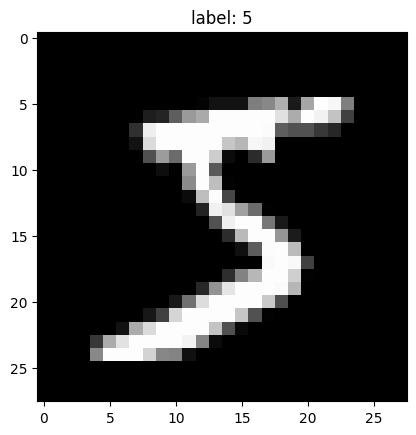

(784,) 0.0 1.0


In [1]:
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt

(x_train, y_train), (x_test, y_test) = mnist.load_data()
# (x_train[0], y_train[0]) = ([image of 5], 5)
print(x_train.shape, y_train.shape)
print(x_test.shape, y_test.shape)

plt.imshow(x_train[0], cmap="gray")
plt.title("label: " + str(y_train[0]))
plt.show()

x = x_train[0].reshape(784) / 255
print(x.shape, x.min(), x.max())

In [2]:
print("Dimension of image:", x_train[0].shape)

Dimension of image: (28, 28)


# Designing epoch based on the first image

In [3]:
import numpy as np
x_input = x_train[0].flatten() / 255
input_layer_neuron_count = x_input.shape[0]
input_layer_neuron_count
h1_layer_neuron_count = 16
h2_layer_neuron_count = 16
output_layer_neuron_count = 10

# Weight matrix initialization for Input to H1 layer

In [4]:
import pandas as pd
rng = np.random.default_rng(42)
# weight_matrix_input_to_h1 = np.random.rand(h1_layer_neuron_count, input_layer_neuron_count)
weight_matrix_input_to_h1 = rng.normal(0, 1/np.sqrt(784), (16, 784))
weight_matrix_input_to_h1_df = pd.DataFrame(
  weight_matrix_input_to_h1, 
  index=[f"h1_{i}" for i in range(h1_layer_neuron_count)],
  columns=[f"i_{i}" for i in range(input_layer_neuron_count)] 
)
weight_matrix_input_to_h1_df

,i_0,i_1,i_2,i_3,i_4,i_5,i_6,i_7,i_8,i_9,...,i_774,i_775,i_776,i_777,i_778,i_779,i_780,i_781,i_782,i_783
h1_0,0.010883,-0.037142,0.026802,0.033592,-0.069680,-0.046506,0.004566,-0.011294,-0.000600,-0.030466,...,0.000430,0.007243,-0.039053,0.014178,0.002157,-0.046523,-0.001828,-0.002847,0.064199,0.031936
h1_1,0.000409,0.008885,0.001579,-0.007247,-0.038658,-0.005395,-0.026646,-0.044654,0.018258,0.013974,...,0.028897,-0.005208,-0.014001,0.004997,-0.029163,-0.040958,-0.033579,-0.022672,-0.041553,0.005788
h1_2,0.026061,-0.056682,0.000897,-0.007855,0.012197,-0.000462,-0.051914,-0.045085,0.001051,0.036742,...,-0.073384,-0.006735,0.028991,-0.034636,-0.006299,-0.024706,0.053644,0.026766,0.023269,0.022200
h1_3,-0.001330,0.007056,-0.042328,-0.078087,0.005360,0.011571,0.043188,0.056119,0.056071,-0.035644,...,-0.001524,0.014746,-0.025934,0.013204,0.023872,-0.023917,0.001851,-0.022272,-0.018804,-0.040176
h1_4,0.045206,0.038060,0.019194,0.070436,-0.006759,0.108277,-0.008126,0.009114,-0.014206,0.013297,...,0.048307,0.086516,-0.016991,-0.047158,-0.079890,-0.008718,-0.011299,-0.023261,0.007906,0.014113
h1_5,0.011539,-0.011290,-0.039344,0.023780,0.000447,0.031727,0.028217,-0.050777,-0.051222,-0.026984,...,-0.004322,0.012893,0.025578,-0.003353,0.038540,0.000285,0.028316,-0.017495,-0.064735,0.009584
h1_6,0.025904,0.020548,0.015078,-0.012450,-0.028812,0.019705,0.015230,-0.020032,0.039622,-0.031531,...,0.031668,-0.035202,0.023951,-0.019026,0.000589,0.050605,0.028839,0.028424,0.068171,-0.025139
h1_7,-0.035210,-0.025790,-0.009089,-0.084091,-0.007408,-0.019449,0.027991,0.012586,-0.021453,0.021070,...,-0.011501,-0.023158,0.001841,-0.040963,0.015314,0.040407,-0.002829,-0.007237,0.013337,-0.072445
h1_8,0.019172,0.110782,-0.004381,-0.004254,0.026557,0.058762,0.034820,-0.076986,0.020121,0.091855,...,0.020409,0.025933,0.009782,0.035621,0.018538,0.062889,0.018655,0.070166,0.032181,-0.064491
h1_9,0.093254,-0.020512,0.053412,0.000957,0.037896,-0.024589,0.022348,-0.009043,0.056393,0.015667,...,0.073906,0.075793,0.010074,0.019736,0.042560,-0.042400,-0.046857,0.044872,0.009785,-0.008089


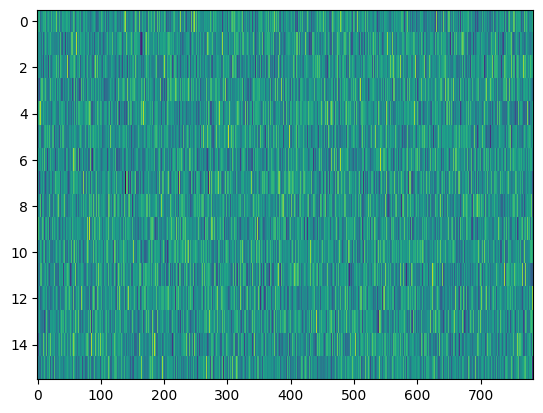

In [5]:
weight_matrix_input_to_h1_df = pd.DataFrame(
  weight_matrix_input_to_h1, 
  index=[f"h1_{i}" for i in range(h1_layer_neuron_count)],
  columns=[f"i_{i}" for i in range(input_layer_neuron_count)] 
)
plt.imshow(weight_matrix_input_to_h1_df, aspect="auto", cmap="viridis", interpolation="nearest")

# Weight matrx initialization for H1 to H2 layer

In [6]:
# weight_matrix_h1_to_h2 = np.random.rand(h2_layer_neuron_count, h1_layer_neuron_count)
weight_matrix_h1_to_h2    = rng.normal(0, 1/np.sqrt(16),  (16, 16))
weight_matrix_h1_to_h2_df = pd.DataFrame(
  weight_matrix_h1_to_h2,
  columns=[f"H1_{i}" for i in range(h1_layer_neuron_count)],
  index=[f"H2_{i}" for i in range(h2_layer_neuron_count)]
)
weight_matrix_h1_to_h2_df

,H1_0,H1_1,H1_2,H1_3,H1_4,H1_5,H1_6,H1_7,H1_8,H1_9,H1_10,H1_11,H1_12,H1_13,H1_14,H1_15
H2_0,0.419568,-0.074398,-0.205820,-0.281028,-0.084111,-0.140687,-0.184252,-0.170532,0.132436,0.507591,0.205143,0.280650,-0.094353,0.026166,0.106621,-0.164889
H2_1,-0.106433,0.213638,0.272573,0.016853,-0.298789,-0.073898,-0.360333,0.018801,0.063851,-0.067678,0.060428,0.104225,0.064216,-0.300383,-0.063316,0.102461
H2_2,0.394678,-0.067981,0.137710,0.219538,-0.049157,0.287102,0.300543,0.345096,0.114608,0.590034,-0.153821,0.531019,0.192075,0.335097,-0.080009,0.211119
H2_3,0.356744,-0.271840,-0.040832,-0.535313,-0.044583,-0.204002,-0.054442,0.730911,0.429451,-0.359862,0.138935,0.199733,-0.084474,0.044577,0.068996,-0.336653
H2_4,-0.257832,0.043074,0.024851,-0.177141,-0.198594,-0.022445,0.221538,-0.019121,0.405683,-0.173955,0.048277,-0.088574,0.146990,-0.195397,0.481849,-0.422653
H2_5,0.428870,0.022497,0.138106,0.333631,0.214415,-0.182507,0.150022,0.466868,-0.221823,0.529607,0.096426,-0.108307,-0.223322,-0.055822,-0.488820,-0.103811
H2_6,-0.065732,-0.268603,0.186961,-0.054692,-0.158949,-0.081333,0.088777,0.018305,-0.175244,0.031413,-0.012669,-0.284866,-0.072126,0.144835,0.143035,-0.057491
H2_7,0.169193,-0.244989,-0.237247,-0.062814,0.374392,0.040813,-0.068841,0.386035,-0.071735,0.558683,-0.127821,-0.252932,-0.041590,-0.062271,-0.201930,0.650494
H2_8,0.079657,0.116062,-0.115470,-0.144417,0.256390,-0.418960,-0.285716,-0.061827,0.337762,-0.093629,0.104038,0.006932,0.324065,-0.396181,0.183991,-0.049725
H2_9,0.231221,-0.204821,0.006098,-0.025627,-0.250609,-0.320103,-0.145103,0.032483,-0.189228,-0.082518,-0.471449,-0.092662,0.255897,0.176295,-0.021730,0.060913


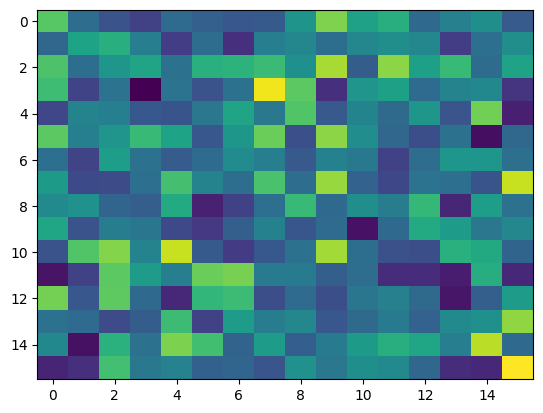

In [7]:
weight_matrix_h1_to_h2_df = pd.DataFrame(
  weight_matrix_h1_to_h2,
  columns=[f"H1_{i}" for i in range(h1_layer_neuron_count)],
  index=[f"H2_{i}" for i in range(h2_layer_neuron_count)]
)
plt.imshow(weight_matrix_h1_to_h2_df, aspect="auto", cmap="viridis", interpolation="nearest")

# Weight Matrix initialization for H2 to Output layer

In [8]:
# weight_matrix_h2_to_output = np.random.rand(output_layer_neuron_count, h2_layer_neuron_count)
weight_matrix_h2_to_output = rng.normal(0, 1/np.sqrt(16), (10, 16))
weight_matrix_h2_to_output_df = pd.DataFrame(
  weight_matrix_h2_to_output,
  index=[f"O_{i}" for i in range(output_layer_neuron_count)],
  columns=[f"H2_{i}" for i in range(h2_layer_neuron_count)]
)
weight_matrix_h2_to_output_df

,H2_0,H2_1,H2_2,H2_3,H2_4,H2_5,H2_6,H2_7,H2_8,H2_9,H2_10,H2_11,H2_12,H2_13,H2_14,H2_15
O_0,0.369543,0.335046,-0.168652,0.002377,-0.203841,-0.328021,-0.147193,0.331546,0.210186,-0.242512,-0.078704,0.187281,-0.142743,0.019897,0.100462,0.097733
O_1,0.063536,-0.163424,-0.137744,-0.283412,-0.390334,-0.028687,0.204065,-0.345071,0.068243,0.196158,-0.459183,-0.067645,0.411553,0.137985,-0.467614,0.164585
O_2,-0.186934,0.172827,-0.172520,-0.013258,-0.134386,0.000789,-0.141820,-0.055885,-0.293901,0.122665,0.043821,-0.404133,0.248229,-0.044072,0.040441,0.191140
O_3,0.082061,0.291301,-0.073324,0.258607,0.030731,0.126908,0.100907,0.310183,0.180353,-0.110736,-0.160317,-0.012439,-0.190025,-0.263048,-0.532013,-0.387316
O_4,0.496352,-0.164125,0.475865,0.100789,-0.012440,-0.375151,0.001167,0.473046,0.389409,0.068560,-0.287167,-0.239291,-0.213148,0.319539,0.407930,0.048973
O_5,-0.075770,0.387178,-0.244643,0.012956,0.115741,-0.215700,-0.158979,-0.178434,0.354182,0.478592,0.028698,-0.067055,-0.149960,0.000437,-0.137555,-0.024258
O_6,0.103308,-0.101328,-0.047397,-0.046364,-0.079391,-0.110362,0.190549,-0.442684,0.393570,0.033882,0.152504,0.181269,-0.177015,-0.228590,-0.258067,-0.061767
O_7,0.174801,-0.145941,0.151983,-0.591980,-0.096392,0.291784,-0.042743,-0.207286,-0.164211,-0.757006,-0.252950,0.264310,-0.145651,-0.116136,-0.582953,-0.407709
O_8,0.297512,0.154324,-0.324360,-0.157643,-0.007293,-0.299032,-0.501036,-0.039803,0.143152,0.147964,0.218809,-0.388389,0.014475,-0.067113,-0.021805,-0.052945
O_9,-0.165112,-0.754448,0.290457,0.082498,-0.371072,0.118283,-0.111826,-0.104743,-0.192104,0.134233,-0.199956,-0.274209,0.282936,-0.044720,-0.036872,0.173116


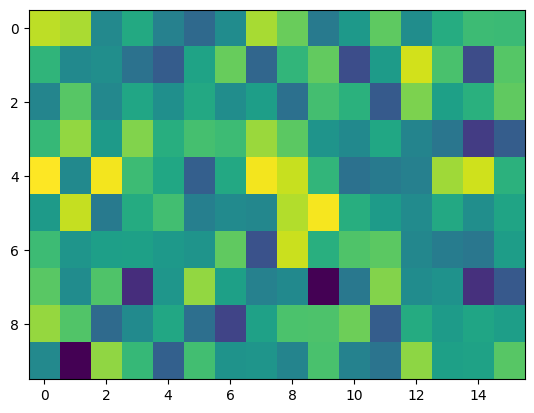

In [9]:
weight_matrix_h2_to_output_df = pd.DataFrame(
  weight_matrix_h2_to_output,
  index=[f"O_{i}" for i in range(output_layer_neuron_count)],
  columns=[f"H2_{i}" for i in range(h2_layer_neuron_count)]
)
plt.imshow(weight_matrix_h2_to_output_df, aspect="auto", cmap="viridis", interpolation="nearest")

# Bias initialization

In [10]:
bias_h1 = np.random.rand(h1_layer_neuron_count)
bias_h2 = np.random.rand(h2_layer_neuron_count)
bias_o = np.random.rand(output_layer_neuron_count)
print(f"Bias 1st hidden layer: {bias_h1}")
print(f"Bias 2nd hidden layer: {bias_h2}")
print(f"Bias Output layer: {bias_o}")

Bias 1st hidden layer: [3.75007533e-04 5.40797821e-01 6.64941971e-01 1.10267481e-01
 1.73148805e-01 4.67701158e-01 1.27378603e-01 8.08203153e-01
 7.69231976e-01 8.63786986e-01 2.27979938e-01 2.59685046e-01
 2.28200946e-01 6.19543422e-01 3.06024863e-01 2.98112323e-01]
Bias 2nd hidden layer: [0.67210658 0.02699293 0.91547282 0.05149494 0.91869985 0.42226836
 0.15514913 0.76803286 0.70077044 0.70047668 0.52618054 0.45314186
 0.09538003 0.54873343 0.72663271 0.22377757]
Bias Output layer: [0.22344295 0.28733769 0.65134451 0.64668507 0.59729129 0.29149597
 0.7030871  0.33855859 0.19034962 0.02145626]


# Forward Pass

In [11]:
sigmoid = lambda x: (1 / (1 + np.exp(-x)))
z_h1 = sigmoid((weight_matrix_input_to_h1 @ x_input) + bias_h1)
z_h1

array([0.48222374, 0.65665622, 0.57490693, 0.52310275, 0.63435076,
       0.63257252, 0.52455941, 0.7172728 , 0.73289674, 0.6060573 ,
       0.6601577 , 0.59962797, 0.58683515, 0.57916378, 0.49415439,
       0.6678801 ])

In [12]:
z_h2 = sigmoid((weight_matrix_h1_to_h2 @ z_h1) + bias_h2)
z_h2

array([0.6920399 , 0.46970863, 0.94672259, 0.54327263, 0.6912925 ,
       0.73394867, 0.43011892, 0.79376265, 0.65901978, 0.49500774,
       0.77450802, 0.4948691 , 0.47941002, 0.66111494, 0.85316608,
       0.49337024])

In [13]:
z_o = sigmoid((weight_matrix_h2_to_output @ z_h2) + bias_o)
z_o

array([0.60473171, 0.31364785, 0.53857291, 0.58397377, 0.86898408,
       0.54152107, 0.56191663, 0.22876264, 0.41753205, 0.3500062 ])

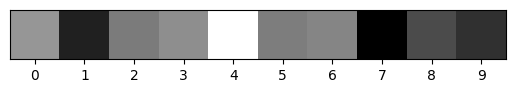

In [14]:
plt.imshow(np.array([z_o]), cmap="gray")
plt.xticks(range(10))
plt.yticks([])
plt.show()

# Backpropagation

In [15]:
# # Output -> H2 Layer
# r = 0.1
# o_slope_z = np.zeros(output_layer_neuron_count)
# new_weight_matrix_h2_to_output = np.zeros((output_layer_neuron_count, h2_layer_neuron_count))
# for i in range(output_layer_neuron_count):
#   t = 1 if y_train[0] == i else 0
#   ws_slope_i = 2 * (z_o[i] - t)
#   o_slope_z[i] = ws_slope_i
#   new_weight_vector_h2_to_i = weight_matrix_h2_to_output[i] - r * ws_slope_i * z_h2
#   new_weight_matrix_h2_to_output[i] = new_weight_vector_h2_to_i

In [16]:
# # H2 -> H1
# h2_slope_z = np.zeros(h2_layer_neuron_count)
# new_weight_matrix_h1_to_h2 = np.zeros((h2_layer_neuron_count, h1_layer_neuron_count))
# for i in range(h2_layer_neuron_count):
#   ws_slope_i = z_h2[i] * (1 - z_h2[i]) * sum(o_slope_z[j] * weight_matrix_h2_to_output[j][i] for j in range(output_layer_neuron_count))
#   h2_slope_z[i] = ws_slope_i
#   new_weight_matrix_h1_to_h2[i] = weight_matrix_h1_to_h2[i] - r * ws_slope_i * z_h1

In [17]:
# # H1 -> Input
# new_weight_matrix_input_to_h1 = np.zeros((h1_layer_neuron_count, input_layer_neuron_count))
# for i in range(h1_layer_neuron_count):
#   ws_slope_i = z_h1[i] * (1 - z_h1[i]) * sum(h2_slope_z[j] * weight_matrix_h1_to_h2[j][i] for j in range(h2_layer_neuron_count))
#   new_weight_matrix_input_to_h1[i] = weight_matrix_input_to_h1[i] - r * ws_slope_i * x_input

# Backpropagation generalization

In [18]:
def backprop(correct_number: int):
  # Output -> H2 Layer
  r = 0.1
  o_slope_z = np.zeros(output_layer_neuron_count)
  new_weight_matrix_h2_to_output = np.zeros((output_layer_neuron_count, h2_layer_neuron_count))
  for i in range(output_layer_neuron_count):
    t = 1 if correct_number == i else 0
    ws_slope_i = 2 * (z_o[i] - t)
    o_slope_z[i] = ws_slope_i
    new_weight_vector_h2_to_i = weight_matrix_h2_to_output[i] - r * ws_slope_i * z_h2
    new_weight_matrix_h2_to_output[i] = new_weight_vector_h2_to_i

  # H2 -> H1
  h2_slope_z = np.zeros(h2_layer_neuron_count)
  new_weight_matrix_h1_to_h2 = np.zeros((h2_layer_neuron_count, h1_layer_neuron_count))
  for i in range(h2_layer_neuron_count):
    ws_slope_i = z_h2[i] * (1 - z_h2[i]) * sum(o_slope_z[j] * weight_matrix_h2_to_output[j][i] for j in range(output_layer_neuron_count))
    h2_slope_z[i] = ws_slope_i
    new_weight_matrix_h1_to_h2[i] = weight_matrix_h1_to_h2[i] - r * ws_slope_i * z_h1

  # H1 -> Input
  h1_slope_z = np.zeros(h1_layer_neuron_count)
  new_weight_matrix_input_to_h1 = np.zeros((h1_layer_neuron_count, input_layer_neuron_count))
  for i in range(h1_layer_neuron_count):
    ws_slope_i = z_h1[i] * (1 - z_h1[i]) * sum(h2_slope_z[j] * weight_matrix_h1_to_h2[j][i] for j in range(h2_layer_neuron_count))
    h1_slope_z[i] = ws_slope_i
    new_weight_matrix_input_to_h1[i] = weight_matrix_input_to_h1[i] - r * ws_slope_i * x_input

   # Biases
  new_bias_o = bias_o - r * o_slope_z
  new_bias_h2 = bias_h2 - r * h2_slope_z
  new_bias_h1 = bias_h1 - r * h1_slope_z

  return (new_weight_matrix_h2_to_output, new_weight_matrix_h1_to_h2, new_weight_matrix_input_to_h1,
          new_bias_o, new_bias_h2, new_bias_h1)

# Forward pass generalization

In [19]:
def forward_pass(image):
  global x_input, z_h1, z_h2, z_o, weight_matrix_input_to_h1, weight_matrix_h1_to_h2, weight_matrix_h2_to_output
  x_input = image.flatten() / 255
  sigmoid = lambda x: (1 / (1 + np.exp(-x)))
  z_h1 = sigmoid((weight_matrix_input_to_h1 @ x_input) + bias_h1)
  z_h2 = sigmoid((weight_matrix_h1_to_h2 @ z_h1) + bias_h2)
  z_o = sigmoid((weight_matrix_h2_to_output @ z_h2) + bias_o)

# Epoch's

In [20]:
for i in range(len(x_train)):
  image = x_train[i]
  number = y_train[i]
  forward_pass(image)
  new_weight_matrix_h2_to_output, new_weight_matrix_h1_to_h2, new_weight_matrix_input_to_h1, new_bias_o, new_bias_h2, new_bias_h1 = backprop(number)
  weight_matrix_input_to_h1 = new_weight_matrix_input_to_h1
  weight_matrix_h1_to_h2 = new_weight_matrix_h1_to_h2
  weight_matrix_h2_to_output = new_weight_matrix_h2_to_output
  bias_h1 = new_bias_h1
  bias_h2 = new_bias_h2
  bias_o = new_bias_o
  
  print(f"Epoch finished: {i}")
  # plt.imshow(np.array([z_o]), cmap="gray")
  # plt.title(f"Prediction for: {number}")
  # plt.xticks(range(10))
  # plt.yticks([])
  # plt.show()
  

Epoch finished: 0
Epoch finished: 1
Epoch finished: 2
Epoch finished: 3
Epoch finished: 4
Epoch finished: 5
Epoch finished: 6
Epoch finished: 7
Epoch finished: 8
Epoch finished: 9
Epoch finished: 10
Epoch finished: 11
Epoch finished: 12
Epoch finished: 13
Epoch finished: 14
Epoch finished: 15
Epoch finished: 16
Epoch finished: 17
Epoch finished: 18
Epoch finished: 19
Epoch finished: 20
Epoch finished: 21
Epoch finished: 22
Epoch finished: 23
Epoch finished: 24
Epoch finished: 25
Epoch finished: 26
Epoch finished: 27
Epoch finished: 28
Epoch finished: 29
Epoch finished: 30
Epoch finished: 31
Epoch finished: 32
Epoch finished: 33
Epoch finished: 34
Epoch finished: 35
Epoch finished: 36
Epoch finished: 37
Epoch finished: 38
Epoch finished: 39
Epoch finished: 40
Epoch finished: 41
Epoch finished: 42
Epoch finished: 43
Epoch finished: 44
Epoch finished: 45
Epoch finished: 46
Epoch finished: 47
Epoch finished: 48
Epoch finished: 49
Epoch finished: 50
Epoch finished: 51
Epoch finished: 52
Epo

# Testing

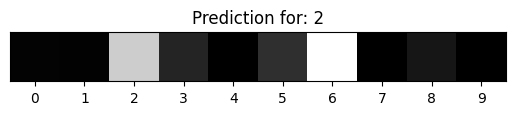

1.0186385922034296e-57 1.0
[4.26935758e-03 2.74082081e-03 2.25452079e-01 4.15419784e-02
 9.85270187e-05 5.23687789e-02 2.81381511e-01 2.84938565e-05
 2.50073478e-02 1.96537469e-04]


In [21]:
image_no = 1
forward_pass(x_test[image_no])
plt.imshow(np.array([z_o]), cmap="gray")
plt.title(f"Prediction for: {y_test[image_no]}")
plt.xticks(range(10))
plt.yticks([])
plt.show()
print(z_h1.min(), z_h1.max())
print(z_o)

In [22]:
tested = 0
correct = 0
for i in range(len(x_test)):
  tested += 1
  print(f"Tested: {tested}")
  forward_pass(x_test[i])
  prediction = np.argmax(z_o)
  if prediction == y_test[i]:
    correct += 1
accuracy = (correct * 100 / tested)
print("Accuracy: ", accuracy)

Tested: 1
Tested: 2
Tested: 3
Tested: 4
Tested: 5
Tested: 6
Tested: 7
Tested: 8
Tested: 9
Tested: 10
Tested: 11
Tested: 12
Tested: 13
Tested: 14
Tested: 15
Tested: 16
Tested: 17
Tested: 18
Tested: 19
Tested: 20
Tested: 21
Tested: 22
Tested: 23
Tested: 24
Tested: 25
Tested: 26
Tested: 27
Tested: 28
Tested: 29
Tested: 30
Tested: 31
Tested: 32
Tested: 33
Tested: 34
Tested: 35
Tested: 36
Tested: 37
Tested: 38
Tested: 39
Tested: 40
Tested: 41
Tested: 42
Tested: 43
Tested: 44
Tested: 45
Tested: 46
Tested: 47
Tested: 48
Tested: 49
Tested: 50
Tested: 51
Tested: 52
Tested: 53
Tested: 54
Tested: 55
Tested: 56
Tested: 57
Tested: 58
Tested: 59
Tested: 60
Tested: 61
Tested: 62
Tested: 63
Tested: 64
Tested: 65
Tested: 66
Tested: 67
Tested: 68
Tested: 69
Tested: 70
Tested: 71
Tested: 72
Tested: 73
Tested: 74
Tested: 75
Tested: 76
Tested: 77
Tested: 78
Tested: 79
Tested: 80
Tested: 81
Tested: 82
Tested: 83
Tested: 84
Tested: 85
Tested: 86
Tested: 87
Tested: 88
Tested: 89
Tested: 90
Tested: 91
Tested: 

# Manual Testing

In [23]:
def test_prediction(image_no: int):
  plt.title(f"Number: {y_test[image_no]}")
  plt.imshow(x_test[image_no], cmap="gray")
  forward_pass(x_test[image_no])
  print(f"Predicted: {np.argmax(z_o)}")

Predicted: 1


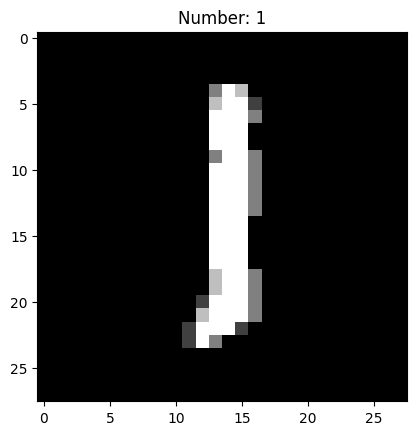

In [24]:
test_prediction(14)

In [25]:
np.savez("hand-written-digit-detection-model.npz",
         weight_matrix_input_to_h1=weight_matrix_input_to_h1,
         weight_matrix_h1_to_h2=weight_matrix_h1_to_h2,
         weight_matrix_h2_to_output=weight_matrix_h2_to_output,
         bias_h1=bias_h1,
         bias_h2=bias_h2,
         bias_o=bias_o)